<a href="https://colab.research.google.com/github/ChristZ-coderFs/ITC3154-Customer-Churn/blob/petros-residual/Petros_Residual_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MLP for Customer Churn Prediction - Petros

Environment Setup, Reproducibility & Data Integrity Verification

In [2]:
import os
import json
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
)

# Folder for saving results and plots
os.makedirs("residual_outputs", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def set_res_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Load prepared datasets
res_train_df = pd.read_csv("/content/churn_train.csv")
res_val_df = pd.read_csv("/content/churn_validation.csv")
res_test_df = pd.read_csv("/content/churn_test.csv")

# Basic checks to make sure data is clean and aligned
assert list(res_train_df.columns) == list(res_val_df.columns) == list(res_test_df.columns)
assert res_train_df.isnull().sum().sum() == 0
assert res_val_df.isnull().sum().sum() == 0
assert res_test_df.isnull().sum().sum() == 0

res_feature_cols = [col for col in res_train_df.columns if col != "Churn"]
assert len(res_feature_cols) == 45

print("Train shape:", res_train_df.shape, "| Churn %:", round(res_train_df["Churn"].mean() * 100, 2))
print("Val shape:  ", res_val_df.shape, "| Churn %:", round(res_val_df["Churn"].mean() * 100, 2))
print("Test shape: ", res_test_df.shape, "| Churn %:", round(res_test_df["Churn"].mean() * 100, 2))

# Convert dataframes to PyTorch tensors
X_train_res = torch.tensor(res_train_df[res_feature_cols].values, dtype=torch.float32)
y_train_res = torch.tensor(res_train_df["Churn"].values, dtype=torch.float32)

X_val_res = torch.tensor(res_val_df[res_feature_cols].values, dtype=torch.float32)
y_val_res = torch.tensor(res_val_df["Churn"].values, dtype=torch.float32)

X_test_res = torch.tensor(res_test_df[res_feature_cols].values, dtype=torch.float32)
y_test_res = torch.tensor(res_test_df["Churn"].values, dtype=torch.float32)

Using device: cpu
Train shape: (4930, 46) | Churn %: 26.53
Val shape:   (1056, 46) | Churn %: 26.52
Test shape:  (1057, 46) | Churn %: 26.58


Residual MLP Architecture Definition & Forward-Pass Smoke Test

In [3]:
class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(hidden_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        out = self.relu(out + x)  # skip connection: h = ReLU(x + F(x))
        return out


class ResidualMLP(nn.Module):
    def __init__(self, input_dim=45, hidden_dim=64, num_blocks=2):
        super().__init__()
        self.input_projection = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU()
        )
        self.blocks = nn.ModuleList([ResidualBlock(hidden_dim) for _ in range(num_blocks)])
        self.output_head = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        h = self.input_projection(x)
        for block in self.blocks:
            h = block(h)
        logits = self.output_head(h).squeeze(-1)  # raw logit (no sigmoid here)
        return logits


# Quick forward-pass check with dummy data
test_model = ResidualMLP(input_dim=45, hidden_dim=64, num_blocks=2).to(device)
dummy_x = torch.randn(16, 45).to(device)
dummy_out = test_model(dummy_x)

assert dummy_out.shape == (16,)
assert torch.isfinite(dummy_out).all()

res_param_count = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
print("Smoke test passed! Output shape:", dummy_out.shape)
print("Trainable parameters:", res_param_count)

Smoke test passed! Output shape: torch.Size([16])
Trainable parameters: 19649


Training Routine (Early Stopping) & Evaluation Metrics

In [4]:
def compute_res_metrics(y_true, logits, threshold=0.5):
    # Apply sigmoid only during evaluation
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, preds, labels=[0, 1])

    return {
        "accuracy": float(accuracy_score(y_true, preds)),
        "precision": float(precision_score(y_true, preds, zero_division=0)),
        "recall": float(recall_score(y_true, preds, zero_division=0)),
        "f1": float(f1_score(y_true, preds, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probs)),
        "confusion_matrix": cm.tolist(),
        "probs": probs,
        "preds": preds,
    }


def train_res_model(lr, batch_size, seed, max_epochs=100, patience=10):
    set_res_seed(seed)

    train_loader = DataLoader(
        TensorDataset(X_train_res, y_train_res),
        batch_size=batch_size,
        shuffle=True
    )

    res_model = ResidualMLP(input_dim=45, hidden_dim=64, num_blocks=2).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(res_model.parameters(), lr=lr)

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = copy.deepcopy(res_model.state_dict())
    no_improve = 0

    train_losses = []
    val_losses = []

    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        # Training phase
        res_model.train()
        total_loss = 0.0

        for bx, by in train_loader:
            bx = bx.to(device)
            by = by.to(device)

            optimizer.zero_grad()
            logits = res_model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(bx)

        train_losses.append(total_loss / len(X_train_res))

        # Validation phase
        res_model.eval()
        with torch.no_grad():
            val_logits = res_model(X_val_res.to(device))
            val_loss = criterion(val_logits, y_val_res.to(device)).item()
        val_losses.append(val_loss)

        # Early stopping check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_weights = copy.deepcopy(res_model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                break

    train_time = time.time() - start_time
    total_epochs_trained = len(train_losses)

    # Restore best weights before computing final validation metrics
    res_model.load_state_dict(best_weights)
    res_model.eval()
    with torch.no_grad():
        best_val_logits = res_model(X_val_res.to(device)).cpu().numpy()

    val_metrics = compute_res_metrics(y_val_res.numpy(), best_val_logits, threshold=0.5)

    return {
        "model": res_model,
        "best_val_loss": float(best_val_loss),
        "best_epoch": best_epoch,
        "total_epochs_trained": total_epochs_trained,
        "train_time_sec": float(train_time),
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_metrics": val_metrics,
    }

Hyperparameter Grid Search (12 Configurations × 3 Seeds = 36 Runs)

In [5]:
learning_rates = [0.0001, 0.0005, 0.001, 0.005]
batch_sizes = [32, 64, 128]
seeds = [42, 123, 456]

all_runs = []
trained_runs = {}
config_id = 0

for lr in learning_rates:
    for bs in batch_sizes:
        config_id += 1
        is_baseline = (lr == 0.001 and bs == 64)

        for seed in seeds:
            run = train_res_model(lr=lr, batch_size=bs, seed=seed, max_epochs=100, patience=10)
            trained_runs[(lr, bs, seed)] = run
            vm = run["val_metrics"]

            all_runs.append({
                "config_id": config_id,
                "is_baseline": is_baseline,
                "lr": lr,
                "batch_size": bs,
                "seed": seed,
                "best_epoch": run["best_epoch"],
                "total_epochs_trained": run["total_epochs_trained"],
                "train_time_sec": round(run["train_time_sec"], 4),
                "val_loss": round(run["best_val_loss"], 6),
                "val_accuracy": round(vm["accuracy"], 4),
                "val_precision": round(vm["precision"], 4),
                "val_recall": round(vm["recall"], 4),
                "val_f1": round(vm["f1"], 4),
                "val_roc_auc": round(vm["roc_auc"], 4),
            })

# Save all 36 individual runs
runs_df = pd.DataFrame(all_runs)
runs_df.to_csv("residual_outputs/residual_all_36_runs.csv", index=False)

# Average metrics across the 3 seeds for each configuration
summary_rows = []
for (cid, base, lr, bs), group in runs_df.groupby(["config_id", "is_baseline", "lr", "batch_size"]):
    summary_rows.append({
        "config_id": cid,
        "is_baseline": base,
        "lr": lr,
        "batch_size": bs,
        "mean_val_loss": group["val_loss"].mean(),
        "std_val_loss": group["val_loss"].std(),
        "mean_val_acc": group["val_accuracy"].mean(),
        "mean_val_f1": group["val_f1"].mean(),
        "std_val_f1": group["val_f1"].std(),
        "mean_val_roc_auc": group["val_roc_auc"].mean(),
        "mean_best_epoch": group["best_epoch"].mean(),
        "mean_total_epochs": group["total_epochs_trained"].mean(),
        "mean_train_time_sec": group["train_time_sec"].mean(),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("mean_val_loss").reset_index(drop=True)
summary_df.to_csv("residual_outputs/residual_tuning_summary.csv", index=False)

best_lr = float(summary_df.loc[0, "lr"])
best_bs = int(summary_df.loc[0, "batch_size"])

print("Grid search complete (36 runs).")
print(f"Best config -> lr={best_lr}, batch_size={best_bs}, mean_val_loss={summary_df.loc[0, 'mean_val_loss']:.6f}")
summary_df

Grid search complete (36 runs).
Best config -> lr=0.005, batch_size=64, mean_val_loss=0.418165


,config_id,is_baseline,lr,batch_size,mean_val_loss,std_val_loss,mean_val_acc,mean_val_f1,std_val_f1,mean_val_roc_auc,mean_best_epoch,mean_total_epochs,mean_train_time_sec
0,11,False,0.0050,64,0.418165,0.000512,0.806833,0.591033,0.017103,0.845633,4.333333,14.333333,2.721367
1,6,False,0.0005,128,0.419754,0.001808,0.805233,0.591133,0.004759,0.843167,9.333333,19.333333,2.510900
2,10,False,0.0050,32,0.419832,0.000894,0.805267,0.601967,0.009548,0.845433,4.333333,14.333333,4.451367
3,1,False,0.0001,32,0.419886,0.001708,0.802400,0.590267,0.004908,0.843133,19.666667,29.666667,11.729900
4,4,False,0.0005,32,0.420272,0.000223,0.805233,0.597200,0.013471,0.843300,5.333333,15.333333,4.447767
5,2,False,0.0001,64,0.420332,0.001927,0.803033,0.597833,0.008690,0.843000,29.333333,39.333333,6.998233
6,12,False,0.0050,128,0.420358,0.001208,0.806533,0.595667,0.011068,0.843467,3.000000,13.000000,1.295233
7,3,False,0.0001,128,0.420428,0.002053,0.802700,0.594267,0.013045,0.842767,40.666667,50.666667,5.732900
8,9,False,0.0010,128,0.420444,0.000822,0.802400,0.598167,0.006839,0.842867,6.000000,16.000000,1.781267
9,5,False,0.0005,64,0.420452,0.000506,0.803667,0.594333,0.013251,0.842700,7.666667,17.666667,3.312133


Held-Out Test Set Evaluation (Initial vs. Tuned) & Artifact Export

In [6]:
def evaluate_on_test(lr, bs, stage_name):
    per_seed = []
    probs_list = []

    for seed in seeds:
        run = trained_runs[(lr, bs, seed)]
        model = run["model"]
        model.eval()
        with torch.no_grad():
            test_logits = model(X_test_res.to(device)).cpu().numpy()

        tm = compute_res_metrics(y_test_res.numpy(), test_logits, threshold=0.5)
        probs_list.append(tm["probs"])

        if seed == 42:
            seed42_metrics = tm

        per_seed.append({
            "seed": seed,
            "best_epoch": run["best_epoch"],
            "total_epochs_trained": run["total_epochs_trained"],
            "train_time_sec": round(run["train_time_sec"], 4),
            "val_loss": round(run["best_val_loss"], 6),
            "test_accuracy": round(tm["accuracy"], 4),
            "test_precision": round(tm["precision"], 4),
            "test_recall": round(tm["recall"], 4),
            "test_f1": round(tm["f1"], 4),
            "test_roc_auc": round(tm["roc_auc"], 4),
            "confusion_matrix": tm["confusion_matrix"],
        })

    df_seed = pd.DataFrame(per_seed)
    summary = {
        "stage": stage_name,
        "model_name": "ResidualMLP",
        "trainable_params": res_param_count,
        "lr": lr,
        "batch_size": bs,
        "threshold": 0.5,
        "seeds": seeds,
        "test_accuracy_mean": float(df_seed["test_accuracy"].mean()),
        "test_accuracy_std": float(df_seed["test_accuracy"].std()),
        "test_precision_mean": float(df_seed["test_precision"].mean()),
        "test_precision_std": float(df_seed["test_precision"].std()),
        "test_recall_mean": float(df_seed["test_recall"].mean()),
        "test_recall_std": float(df_seed["test_recall"].std()),
        "test_f1_mean": float(df_seed["test_f1"].mean()),
        "test_f1_std": float(df_seed["test_f1"].std()),
        "test_roc_auc_mean": float(df_seed["test_roc_auc"].mean()),
        "test_roc_auc_std": float(df_seed["test_roc_auc"].std()),
        "train_time_mean_sec": float(df_seed["train_time_sec"].mean()),
        "best_epoch_mean": float(df_seed["best_epoch"].mean()),
        "total_epochs_mean": float(df_seed["total_epochs_trained"].mean()),
        "seed_42_confusion_matrix": seed42_metrics["confusion_matrix"],
        "per_seed": per_seed,
    }
    return summary, seed42_metrics, np.mean(probs_list, axis=0)


baseline_lr = 0.001
baseline_bs = 64

initial_res, initial_s42, initial_mean_probs = evaluate_on_test(baseline_lr, baseline_bs, "initial")
tuned_res, tuned_s42, tuned_mean_probs = evaluate_on_test(best_lr, best_bs, "tuned")
majority_acc = float((y_test_res.numpy() == 0).mean())

# Save JSON summary for team comparison
results_json = {
    "majority_baseline_accuracy": round(majority_acc, 4),
    "initial": initial_res,
    "tuned": tuned_res,
}
with open("residual_outputs/residual_mlp_results.json", "w") as f:
    json.dump(results_json, f, indent=2)

# Save test set predictions in exact original row order
preds_df = pd.DataFrame({
    "y_true": y_test_res.numpy().astype(int),
    "initial_prob_seed42": initial_s42["probs"],
    "initial_pred_seed42": initial_s42["preds"],
    "initial_prob_mean3seeds": initial_mean_probs,
    "tuned_prob_seed42": tuned_s42["probs"],
    "tuned_pred_seed42": tuned_s42["preds"],
    "tuned_prob_mean3seeds": tuned_mean_probs,
})
preds_df.to_csv("residual_outputs/residual_test_predictions.csv", index=False)

# Print clean comparison table
print(f"Majority Baseline Accuracy: {majority_acc:.4f}\n")
for label, r in [("Initial (lr=0.001, bs=64)", initial_res), (f"Tuned (lr={best_lr}, bs={best_bs})", tuned_res)]:
    print(f"--- {label} ---")
    print(f"Accuracy : {r['test_accuracy_mean']:.4f} +/- {r['test_accuracy_std']:.4f}")
    print(f"Precision: {r['test_precision_mean']:.4f} +/- {r['test_precision_std']:.4f}")
    print(f"Recall   : {r['test_recall_mean']:.4f} +/- {r['test_recall_std']:.4f}")
    print(f"F1 Score : {r['test_f1_mean']:.4f} +/- {r['test_f1_std']:.4f}")
    print(f"ROC-AUC  : {r['test_roc_auc_mean']:.4f} +/- {r['test_roc_auc_std']:.4f}")
    print(f"Avg Time : {r['train_time_mean_sec']:.2f} sec\n")

Majority Baseline Accuracy: 0.7342

--- Initial (lr=0.001, bs=64) ---
Accuracy : 0.7966 +/- 0.0043
Precision: 0.6724 +/- 0.0053
Recall   : 0.4579 +/- 0.0214
F1 Score : 0.5446 +/- 0.0169
ROC-AUC  : 0.8427 +/- 0.0026
Avg Time : 2.66 sec

--- Tuned (lr=0.005, bs=64) ---
Accuracy : 0.8004 +/- 0.0019
Precision: 0.6908 +/- 0.0119
Recall   : 0.4520 +/- 0.0283
F1 Score : 0.5459 +/- 0.0171
ROC-AUC  : 0.8430 +/- 0.0012
Avg Time : 2.72 sec



Diagnostic Visualizations (Loss Curves, Confusion Matrices & ROC Curves)

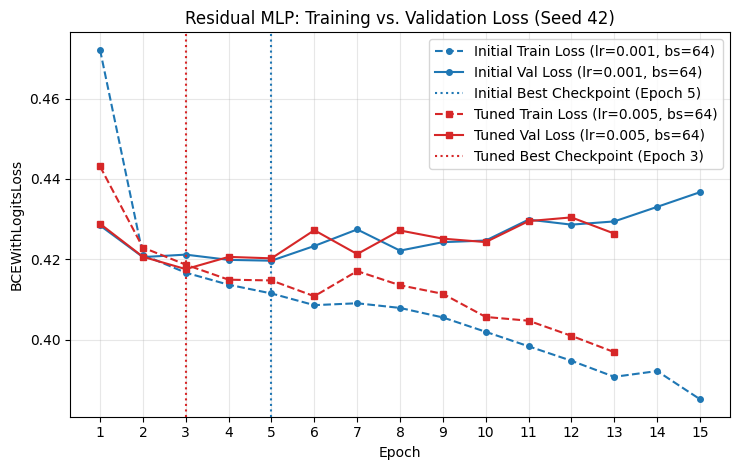

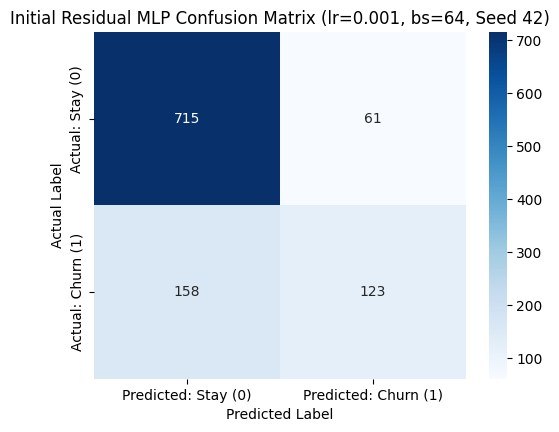

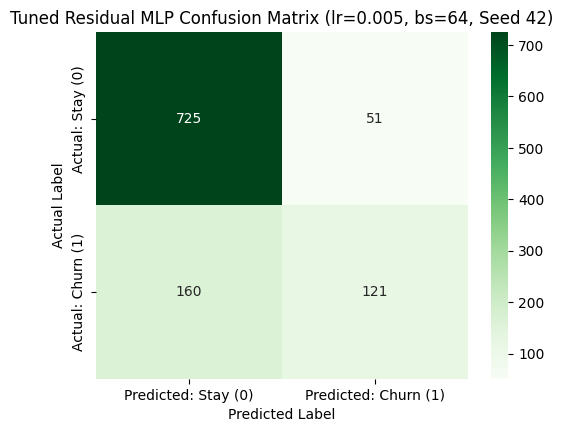

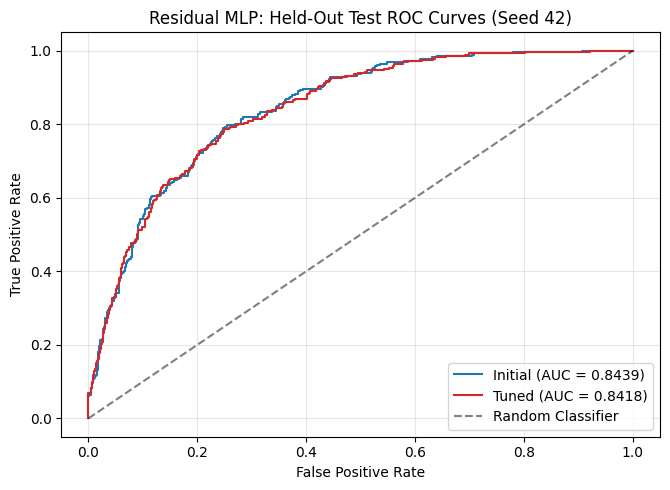

In [7]:
init_run_42 = trained_runs[(baseline_lr, baseline_bs, 42)]
tuned_run_42 = trained_runs[(best_lr, best_bs, 42)]

# Figure 1: Training vs Validation Loss (1-indexed epochs)
ep_init = range(1, len(init_run_42["train_losses"]) + 1)
ep_tuned = range(1, len(tuned_run_42["train_losses"]) + 1)

plt.figure(figsize=(7.5, 4.8))
plt.plot(ep_init, init_run_42["train_losses"], "--o", markersize=4, color="tab:blue", label="Initial Train Loss (lr=0.001, bs=64)")
plt.plot(ep_init, init_run_42["val_losses"], "-o", markersize=4, color="tab:blue", label="Initial Val Loss (lr=0.001, bs=64)")
plt.axvline(init_run_42["best_epoch"], linestyle=":", color="tab:blue", label=f"Initial Best Checkpoint (Epoch {init_run_42['best_epoch']})")

plt.plot(ep_tuned, tuned_run_42["train_losses"], "--s", markersize=4, color="tab:red", label="Tuned Train Loss (lr=0.005, bs=64)")
plt.plot(ep_tuned, tuned_run_42["val_losses"], "-s", markersize=4, color="tab:red", label="Tuned Val Loss (lr=0.005, bs=64)")
plt.axvline(tuned_run_42["best_epoch"], linestyle=":", color="tab:red", label=f"Tuned Best Checkpoint (Epoch {tuned_run_42['best_epoch']})")

plt.title("Residual MLP: Training vs. Validation Loss (Seed 42)")
plt.xlabel("Epoch")
plt.ylabel("BCEWithLogitsLoss")
plt.xticks(range(1, max(len(ep_init), len(ep_tuned)) + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("residual_outputs/fig1_residual_loss_curves.png", dpi=300)
plt.show()

# Figure 2: Initial Residual MLP Confusion Matrix
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    np.array(initial_s42["confusion_matrix"]),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted: Stay (0)", "Predicted: Churn (1)"],
    yticklabels=["Actual: Stay (0)", "Actual: Churn (1)"]
)
plt.title(f"Initial Residual MLP Confusion Matrix (lr={baseline_lr}, bs={baseline_bs}, Seed 42)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.savefig("residual_outputs/fig2_initial_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 3: Tuned Residual MLP Confusion Matrix
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    np.array(tuned_s42["confusion_matrix"]),
    annot=True, fmt="d", cmap="Greens",
    xticklabels=["Predicted: Stay (0)", "Predicted: Churn (1)"],
    yticklabels=["Actual: Stay (0)", "Actual: Churn (1)"]
)
plt.title(f"Tuned Residual MLP Confusion Matrix (lr={best_lr}, bs={best_bs}, Seed 42)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.savefig("residual_outputs/fig3_tuned_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 4: Test Set ROC Curves
fpr_init, tpr_init, _ = roc_curve(y_test_res.numpy(), initial_s42["probs"])
fpr_tuned, tpr_tuned, _ = roc_curve(y_test_res.numpy(), tuned_s42["probs"])

plt.figure(figsize=(6.8, 5))
plt.plot(fpr_init, tpr_init, color="tab:blue", label=f"Initial (AUC = {initial_s42['roc_auc']:.4f})")
plt.plot(fpr_tuned, tpr_tuned, color="tab:red", label=f"Tuned (AUC = {tuned_s42['roc_auc']:.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Classifier")
plt.title("Residual MLP: Held-Out Test ROC Curves (Seed 42)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("residual_outputs/fig4_residual_roc_curves.png", dpi=300)
plt.show()

 Conclusions and Key Takeaways (Residual MLP — Model B)

The 45-to-64 Residual MLP (19,649 trainable parameters across two identity skip blocks) trained stably across all 36 grid-search runs using BCEWithLogitsLoss, Adam, and early stopping (patience = 10). Across the 12 tested configurations and 3 fixed random seeds (42, 123, and 456), a learning rate of 0.005 with a batch size of 64 achieved the lowest mean validation loss (0.4182 ± 0.0005 compared to 0.4208 ± 0.0011 for the initial lr = 0.001, batch size = 64 baseline), reaching its best validation checkpoint within an average of 4.33 epochs and 2.72 seconds per run on CPU.
Evaluated once on the held-out test set of 1,057 customers, the tuned Residual MLP achieved 80.04% ± 0.19% accuracy (+6.62 percentage points above the 73.42% majority-class baseline), 69.08% precision, 45.20% recall, an F1 score of 0.5459, and a ROC-AUC of 0.8430 ± 0.0012. While the high ROC-AUC confirms strong churn-risk ranking discrimination, the network overfits quickly on 4,930 training rows without explicit regularization, and keeping a fixed 0.50 decision threshold under approx.26.5% class imbalance keeps churn recall conservative.
